# TraceableDS — credit-g: benchmark, validators and LLM evaluation (complete pipeline)


| § | Proposal step | What happens |
|---|---|---|
| 1 | A1 | download and freeze the dataset, check selection criteria |
| 2 | A2 | build and execute the correct reference notebook |
| 3 | A3 | create three silent errors: E1 target leakage, E2 preprocessing leakage, E3 test-set misuse |
| 4 | A4 | trace every split, fit and prediction (rows, cells, partitions) |
| 5 | A5 + A6 | deterministic validators VAL_01–03, reduced validator records, gold annotations, QA checks |
| 6 | B1–B3 | prompt (Condition 1 = notebook, Condition 2 = notebook + validator record), masking rules, template baseline |
| 7 | B3 | freeze the protocol (prompt, schema, models, settings) |
| 8 | B4 | generate 4 notebooks × 2 models × 2 conditions = 16 responses via OpenRouter |
| 9 | C | score Metrics 1–4 (automatic part) and write the manual adjudication sheets |
| 10 | — | results: Condition 1 vs. Condition 2, figure, answer texts, report |


In [1]:
!pip -q install nbformat nbclient ipykernel openai

In [2]:
import sys, os, re, json, copy, time, shutil, hashlib, difflib, importlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import sklearn
import nbformat
from nbformat.v4 import new_notebook, new_code_cell, new_markdown_cell
from nbclient import NotebookClient
from sklearn.metrics import roc_auc_score

# ---------------- configuration ----------------
PROJECT_NAME = "traceableds_v2"
DATASET_ID, OPENML_ID, TARGET, POSITIVE = "credit_g", 31, "class", "bad"
DATA_FILE, SIDE_FILE, LEAK_COL = "applicants.csv", "account_reviews.csv", "account_review_score"
SEED = 42
FLIP_RATE = 0.10                                        # E1: share of labels flipped before building the leaked score

MODELS = {"model_a": "meta-llama/llama-3.1-70b-instruct",   # open-weight
          "model_b": "anthropic/claude-opus-4.6"}          # frontier API model
MODEL_ROLES = {"model_a": "open-weight", "model_b": "frontier API"}
GEN_PARAMS = {"temperature": 0, "max_tokens": 1500, "seed": SEED}
MAX_ATTEMPTS = 3                                        # identical stateless calls if a reply is not valid JSON
RUN_ID = "v2_primary"
FREEZE = True                                           # freeze the protocol on first run
RUN_LLM = True                                          # set False to stop before any API call

# ---------------- folders ----------------
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive") / PROJECT_NAME
else:
    ROOT = Path.cwd() / PROJECT_NAME

BENCH = ROOT / "benchmark" / DATASET_ID          # model-facing notebooks and data
META = ROOT / "meta" / DATASET_ID                # hidden: lineage, traces, records, gold
TDS = ROOT / "tds"                               # tracer module (imported by traced notebooks)
PROTOCOL = ROOT / "protocol"
PROMPTS = ROOT / "prompts" / DATASET_ID
RUNS = ROOT / "runs" / RUN_ID / DATASET_ID
BASELINE = ROOT / "runs" / "baseline" / DATASET_ID
SCORING = ROOT / "scoring" / RUN_ID / DATASET_ID
SCORING_BASE = ROOT / "scoring" / "baseline" / DATASET_ID
REPORT = ROOT / "report"
for d in (BENCH, META, META / "traces", META / "records", TDS, PROTOCOL, PROMPTS, RUNS, BASELINE, SCORING, SCORING_BASE, REPORT):
    d.mkdir(parents=True, exist_ok=True)

MOCK = os.environ.get("TDS_MOCK") == "1"         # offline test mode only; never set in Colab

def get_secret(name):
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)

API_KEY = get_secret("OPENROUTER_API_KEY")
assert API_KEY or MOCK or not RUN_LLM, "Add the Colab secret OPENROUTER_API_KEY (key icon, left sidebar)"
print("Project folder:", ROOT)
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| API key:", "found" if API_KEY else "missing")

Mounted at /content/drive
Project folder: /content/drive/MyDrive/traceableds_v2
scikit-learn 1.6.1 | pandas 2.2.3 | API key: found


In [3]:
# ---------------- shared helpers ----------------
def write_json(path, obj):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=str))

def read_json(path):
    return json.loads(Path(path).read_text())

def sha(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()[:16]

def md5_file(path):
    return hashlib.md5(Path(path).read_bytes()).hexdigest()

def now():
    return datetime.now(timezone.utc).isoformat(timespec="seconds")

def cell_ids(nb):
    return [c.metadata["tds_id"] for c in nb.cells]

def sources(nb):
    return {c.metadata["tds_id"]: c.source for c in nb.cells}

def set_source(nb, cid, src):
    next(c for c in nb.cells if c.metadata["tds_id"] == cid).source = src.strip("\n")

def clean_copy(nb):
    nb = copy.deepcopy(nb)
    for c in nb.cells:
        if c.cell_type == "code":
            c.outputs, c.execution_count = [], None
    return nb

def execute(nb, workdir, timeout=900):
    nb = copy.deepcopy(nb)
    NotebookClient(nb, timeout=timeout, kernel_name="python3", resources={"metadata": {"path": str(workdir)}}).execute()
    return nb

def text_outputs(nb):
    out = {}
    for c in nb.cells:
        if c.cell_type != "code" or c.metadata.get("tds_hidden"):
            continue
        parts = []
        for o in c.get("outputs", []):
            if o.output_type == "stream":
                parts.append(o.text)
            elif o.output_type in ("execute_result", "display_data"):
                parts.append(o.get("data", {}).get("text/plain", ""))
            elif o.output_type == "error":
                parts.append(f"ERROR {o.ename}: {o.evalue}")
        out[c.metadata["tds_id"]] = "".join(parts).strip()
    return out

def stderr_outputs(nb):
    return [(c.metadata["tds_id"], o.text[:150]) for c in nb.cells if c.cell_type == "code"
            for o in c.get("outputs", []) if o.output_type == "stream" and o.name == "stderr"]

def grab(pattern, text, cast=float):
    m = re.search(pattern, text)
    return cast(m.group(1)) if m else None

def report_checks(title, checks):
    print(f"--- {title} ---")
    for name, ok in checks.items():
        print(("PASS  " if ok else "FAIL  ") + name)
    assert all(checks.values()), f"{title}: a check failed"

In [4]:
csv_path = BENCH / DATA_FILE
if not csv_path.exists():
    from sklearn.datasets import fetch_openml
    fetch_openml(data_id=OPENML_ID, as_frame=True, parser="auto").frame.to_csv(csv_path, index=False)
df = pd.read_csv(csv_path)
X_all = df.drop(columns=[TARGET])
numeric_cols = X_all.select_dtypes(include="number").columns.tolist()
categorical_cols = X_all.select_dtypes(exclude="number").columns.tolist()
counts = df[TARGET].value_counts()

report_checks("A1 dataset criteria", {
    "binary classification target": df[TARGET].nunique() == 2,
    "1,000-50,000 rows": 1_000 <= len(df) <= 50_000,
    "fewer than 150 input features": X_all.shape[1] < 150,
    "numeric features present (E2 scaler)": len(numeric_cols) > 0,
    "categorical features present": len(categorical_cols) > 0,
    "minority class >= 10%": counts.min() / len(df) >= 0.10,
})
card = {"dataset_id": DATASET_ID, "openml_id": OPENML_ID, "file": DATA_FILE, "md5": md5_file(csv_path),
        "rows": len(df), "features": X_all.shape[1], "numeric": numeric_cols, "categorical": categorical_cols,
        "class_counts": counts.to_dict(), "missing_values": int(df.isna().sum().sum()),
        "environment": {"python": sys.version.split()[0], "sklearn": sklearn.__version__, "pandas": pd.__version__}}
write_json(META / "dataset_card.json", card)
print({k: card[k] for k in ("rows", "features", "class_counts", "missing_values", "md5")})

--- A1 dataset criteria ---
PASS  binary classification target
PASS  1,000-50,000 rows
PASS  fewer than 150 input features
PASS  numeric features present (E2 scaler)
PASS  categorical features present
PASS  minority class >= 10%
{'rows': 1000, 'features': 20, 'class_counts': {'good': 700, 'bad': 300}, 'missing_values': 0, 'md5': 'ac05ce3bfd911258bd37fde1e8a3051f'}


## Correct reference notebook (A2)
Nine steps with stable cell IDs `cell_01`–`cell_09`. Preprocessing sits inside the pipeline, model selection uses
cross-validation on training data only, and the test set is used once. The task text names neither the dataset nor a feature count.

In [5]:
REFERENCE = [
    ("cell_01", "markdown", """# Credit risk classification

**Task.** Predict whether a loan applicant is a good or a bad credit risk from the applicant attributes in `applicants.csv`.
The positive class is `bad`.

**Primary metric.** ROC-AUC on the held-out test set; balanced accuracy and accuracy are reported as well."""),
    ("cell_02", "code", """import numpy as np
import pandas as pd

df = pd.read_csv("applicants.csv")

print("Shape:", df.shape)
print()
print(df.dtypes.value_counts().to_string())
print()
print("Missing values:", int(df.isna().sum().sum()))
print()
print(df["class"].value_counts().to_string())
df.head()"""),
    ("cell_03", "code", """target = "class"
X = df.drop(columns=[target])
y = (df[target] == "bad").astype(int)

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print(f"{len(numeric_features)} numeric features:", numeric_features)
print(f"{len(categorical_features)} categorical features:", categorical_features)
print("Share of bad credit risks:", round(y.mean(), 3))"""),
    ("cell_04", "code", """from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Training set:", X_train.shape, "  Test set:", X_test.shape)
print("Share of bad risks (train / test):", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))"""),
    ("cell_05", "code", """from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ]
)

print("Numeric columns scaled:", len(numeric_features))
print("Categorical columns one-hot encoded:", len(categorical_features))"""),
    ("cell_06", "code", """from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

candidates = {
    "logistic_regression": Pipeline([
        ("prep", clone(preprocessor)),
        ("model", LogisticRegression(max_iter=1000)),
    ]),
    "random_forest": Pipeline([
        ("prep", clone(preprocessor)),
        ("model", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=1)),
    ]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}
for name, pipeline in candidates.items():
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    cv_results[name] = scores
    print(f"{name:<20} CV ROC-AUC: {scores.mean():.3f} (+/- {scores.std():.3f})")"""),
    ("cell_07", "code", """best_name = max(cv_results, key=lambda name: cv_results[name].mean())
final_model = candidates[best_name]
final_model.fit(X_train, y_train)

print("Selected model:", best_name)"""),
    ("cell_08", "code", """from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score

test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= 0.5).astype(int)

print(f"Test ROC-AUC:            {roc_auc_score(y_test, test_proba):.3f}")
print(f"Test balanced accuracy:  {balanced_accuracy_score(y_test, test_pred):.3f}")
print(f"Test accuracy:           {accuracy_score(y_test, test_pred):.3f}")
print(f"Majority-class accuracy: {1 - y_test.mean():.3f}")"""),
    ("cell_09", "markdown", """## Interpretation

The test ROC-AUC above summarises how well the selected model ranks bad credit risks above good ones on applicants
it has not seen. It should be read together with the cross-validation spread: with a small test set, a single test
estimate can easily differ from the cross-validation mean by a few points. Accuracy alone is not very informative here,
because always predicting `good` already reaches the majority-class accuracy shown above, so ROC-AUC and balanced accuracy
are the main indicators. The results describe this split and these two model families; they are not a cost-sensitive
evaluation of lending decisions."""),
]

def build_notebook(specs):
    nb = new_notebook()
    nb.metadata = {"kernelspec": {"name": "python3", "display_name": "Python 3", "language": "python"},
                   "language_info": {"name": "python"}}
    for cid, kind, src in specs:
        c = new_code_cell(src) if kind == "code" else new_markdown_cell(src)
        c["id"], c["metadata"] = cid, {"tds_id": cid}
        nb.cells.append(c)
    nbformat.validate(nb)
    return nb

reference = build_notebook(REFERENCE)
ref_run_1, ref_run_2 = execute(reference, BENCH), execute(reference, BENCH)
ref_out = text_outputs(ref_run_1)
src = sources(reference)
x_test_cells = [cid for cid, s in src.items() if "X_test" in s]

report_checks("A2 reference notebook", {
    "executes and is deterministic (2 runs)": ref_out == text_outputs(ref_run_2),
    "stable ids cell_01..cell_09": cell_ids(reference) == [f"cell_{i:02d}" for i in range(1, 10)],
    "two model families compared": all(m in src["cell_06"] for m in ("LogisticRegression(", "RandomForestClassifier(")),
    "X_test only in split and final evaluation": x_test_cells == ["cell_04", "cell_08"],
    "task text: no dataset name, ID or counts": not re.search(r"\d|german|openml", src["cell_01"], re.I),
    "no warnings": not stderr_outputs(ref_run_1),
})
for cid in ("cell_04", "cell_06", "cell_07", "cell_08"):
    print(f"[{cid}]", ref_out[cid].replace("\n", "\n         "))

--- A2 reference notebook ---
PASS  executes and is deterministic (2 runs)
PASS  stable ids cell_01..cell_09
PASS  two model families compared
PASS  X_test only in split and final evaluation
PASS  task text: no dataset name, ID or counts
PASS  no warnings
[cell_04] Training set: (800, 20)   Test set: (200, 20)
         Share of bad risks (train / test): 0.3 / 0.3
[cell_06] logistic_regression  CV ROC-AUC: 0.771 (+/- 0.053)
         random_forest        CV ROC-AUC: 0.791 (+/- 0.032)
[cell_07] Selected model: random_forest
[cell_08] Test ROC-AUC:            0.789
         Test balanced accuracy:  0.661
         Test accuracy:           0.765
         Majority-class accuracy: 0.700


3 · Three silent errors (A3)
Each mutation edits existing cells only (IDs never change), still executes without warnings, and is reversed exactly by its gold correction.

| Family | Change | Cells |
|---|---|---|
| E1 target leakage | join a side table whose `account_review_score` is a noisy copy of the target | `cell_02` |
| E2 preprocessing leakage | `StandardScaler` fitted on all rows before the split; pipeline uses `passthrough` | `cell_03`, `cell_05` |
| E3 test-set misuse | both models scored on the test set; the higher test score is selected | `cell_07` |

In [6]:
# E1 side table: label flipped for FLIP_RATE of rows, then a score drawn around 64 (bad) or 38 (good); generated once
side_path = BENCH / SIDE_FILE
if not side_path.exists():
    rng = np.random.default_rng(SEED)
    is_bad = (df[TARGET] == POSITIVE).to_numpy()
    noisy = np.where(rng.random(len(df)) < FLIP_RATE, ~is_bad, is_bad)
    score = np.where(noisy, rng.normal(64, 10, len(df)), rng.normal(38, 10, len(df)))
    pd.DataFrame({"applicant_id": np.arange(len(df)),
                  LEAK_COL: np.clip(np.round(score), 0, 100).astype(int)}).to_csv(side_path, index=False)

leak = pd.read_csv(side_path)[LEAK_COL].to_numpy()
is_bad = (df[TARGET] == POSITIVE).to_numpy()
lineage = [{"feature": LEAK_COL, "source_file": SIDE_FILE, "source_md5": md5_file(side_path),
            "derived_from": [TARGET], "introduced_in_cell": "cell_02",
            "derivation": f"label flipped for {FLIP_RATE:.0%} of rows (seed {SEED}); N(64,10) if bad else N(38,10); rounded, clipped 0-100",
            "measured_agreement_with_target": round(float(np.mean((leak >= 51) == is_bad)), 3),
            "measured_roc_auc_alone": round(float(roc_auc_score(is_bad, leak)), 3)}]
write_json(META / "lineage.json", lineage)
print("E1 column, measured:", {k: lineage[0][k] for k in ("measured_agreement_with_target", "measured_roc_auc_alone")})

MUTATIONS = {
    "E1": {"family": "target leakage", "validator": "VAL_01", "root": ["cell_02"], "repair": ["cell_02", "cell_03"],
           "cells": {"cell_02": src["cell_02"].replace(
               'df = pd.read_csv("applicants.csv")\n',
               'df = pd.read_csv("applicants.csv")\nreviews = pd.read_csv("account_reviews.csv", index_col="applicant_id")\ndf = df.join(reviews)\n')}},
    "E2": {"family": "preprocessing leakage", "validator": "VAL_02", "root": ["cell_03"], "repair": ["cell_03", "cell_05"],
           "cells": {"cell_03": "from sklearn.preprocessing import StandardScaler\n\n" + src["cell_03"].replace(
                         'categorical_features = X.select_dtypes(exclude="number").columns.tolist()\n',
                         'categorical_features = X.select_dtypes(exclude="number").columns.tolist()\n\n'
                         'X[numeric_features] = StandardScaler().fit_transform(X[numeric_features])\n'),
                     "cell_05": src["cell_05"].replace("OneHotEncoder, StandardScaler", "OneHotEncoder")
                                               .replace('("num", StandardScaler(), numeric_features)', '("num", "passthrough", numeric_features)')
                                               .replace("Numeric columns scaled:", "Numeric columns:")}},
    "E3": {"family": "test-set misuse", "validator": "VAL_03", "root": ["cell_07"], "repair": ["cell_06", "cell_07"],
           "cells": {"cell_07": """from sklearn.metrics import roc_auc_score

test_scores = {}
for name, pipeline in candidates.items():
    pipeline.fit(X_train, y_train)
    test_scores[name] = roc_auc_score(y_test, pipeline.predict_proba(X_test)[:, 1])
    print(f"{name:<20} ROC-AUC: {test_scores[name]:.3f}")

best_name = max(test_scores, key=test_scores.get)
final_model = candidates[best_name]

print("Selected model:", best_name)"""}},
}

def mutate(nb, label):
    nb = clean_copy(nb)
    for cid, new_src in MUTATIONS[label]["cells"].items():
        set_source(nb, cid, new_src)
    return nb

notebooks = {"correct": clean_copy(reference), **{label: mutate(reference, label) for label in MUTATIONS}}
for label in MUTATIONS:
    for cid, new_src in MUTATIONS[label]["cells"].items():
        assert new_src != src[cid], f"{label}/{cid}: replacement did not apply"
executed = {label: execute(nb, BENCH) for label, nb in notebooks.items()}
outputs = {label: text_outputs(nb) for label, nb in executed.items()}

REVEALING = ["leak", "bug", "mistake", "wrong", "mutation", "error", "cheat", "inflat", "label"]
for label in MUTATIONS:
    mut_src = sources(notebooks[label])
    corrected = clean_copy(notebooks[label])
    for cid in MUTATIONS[label]["cells"]:
        set_source(corrected, cid, src[cid])
    text = " ".join(mut_src.values()) + " " + " ".join(outputs[label].values())
    checks = {
        "executes without warnings": not stderr_outputs(executed[label]),
        "only declared cells changed": [c for c in src if src[c] != mut_src[c]] == list(MUTATIONS[label]["cells"]),
        "cell ids unchanged": cell_ids(notebooks[label]) == cell_ids(reference),
        "task text identical to reference": mut_src["cell_01"] == src["cell_01"],
        "gold correction restores reference code": sources(corrected) == src,
        "no revealing words in code or outputs": not [w for w in REVEALING if w in text.lower()],
    }
    if label == "E1":
        checks["test ROC-AUC below 0.99 (not a give-away)"] = grab(r"Test ROC-AUC:\s+([0-9.]+)", outputs["E1"]["cell_08"]) < 0.99
    report_checks(f"A3 {label}", checks)

effects = pd.DataFrame([{
    "notebook": label,
    "numeric features": grab(r"(\d+) numeric features", o["cell_03"], int),
    "CV AUC logreg": grab(r"logistic_regression\s+CV ROC-AUC: ([0-9.]+)", o["cell_06"]),
    "CV AUC forest": grab(r"random_forest\s+CV ROC-AUC: ([0-9.]+)", o["cell_06"]),
    "selected": grab(r"Selected model: (\w+)", o["cell_07"], str),
    "test AUC": grab(r"Test ROC-AUC:\s+([0-9.]+)", o["cell_08"]),
    "test bal. acc.": grab(r"Test balanced accuracy:\s+([0-9.]+)", o["cell_08"]),
} for label, o in outputs.items()]).set_index("notebook")
effects

E1 column, measured: {'measured_agreement_with_target': 0.818, 'measured_roc_auc_alone': 0.875}
--- A3 E1 ---
PASS  executes without warnings
PASS  only declared cells changed
PASS  cell ids unchanged
PASS  task text identical to reference
PASS  gold correction restores reference code
PASS  no revealing words in code or outputs
PASS  test ROC-AUC below 0.99 (not a give-away)
--- A3 E2 ---
PASS  executes without warnings
PASS  only declared cells changed
PASS  cell ids unchanged
PASS  task text identical to reference
PASS  gold correction restores reference code
PASS  no revealing words in code or outputs
--- A3 E3 ---
PASS  executes without warnings
PASS  only declared cells changed
PASS  cell ids unchanged
PASS  task text identical to reference
PASS  gold correction restores reference code
PASS  no revealing words in code or outputs


,numeric features,CV AUC logreg,CV AUC forest,selected,test AUC,test bal. acc.
notebook,,,,,,
correct,7,0.771,0.791,random_forest,0.789,0.661
E1,8,0.900,0.902,random_forest,0.924,0.830
E2,7,0.770,0.789,random_forest,0.789,0.661
E3,7,0.771,0.791,logistic_regression,0.804,0.710


In [7]:
# neutral file names in a seeded random order; the label mapping stays in the hidden meta folder
labels = ["correct", "E1", "E2", "E3"]
order = np.random.default_rng(SEED).permutation(labels).tolist()
IID = {label: f"{DATASET_ID}_instance_{i + 1}" for i, label in enumerate(order)}
LABEL = {iid: label for label, iid in IID.items()}
for label, iid in IID.items():
    nbformat.write(executed[label], BENCH / f"{iid}.ipynb")

manifest = {"dataset_id": DATASET_ID, "data_md5": card["md5"], "seed": SEED, "effects": effects.reset_index().to_dict("records"),
            "instances": {}}
for label, iid in IID.items():
    m = MUTATIONS.get(label)
    manifest["instances"][iid] = {
        "label": label, "error_present": m is not None, "error_family": m and m["family"],
        "changed_cells": list(m["cells"]) if m else [], "root_cause_cells": m["root"] if m else [],
        "repair_relevant_cells": m["repair"] if m else [], "failing_validator": m and m["validator"],
        "side_files": [SIDE_FILE] if label == "E1" else [],
        "gold_correction": {cid: src[cid] for cid in m["cells"]} if m else {}}
write_json(META / "manifest.json", manifest)
print(json.dumps({iid: label for label, iid in IID.items()}, indent=2))

{
  "credit_g_instance_1": "E3",
  "credit_g_instance_2": "E2",
  "credit_g_instance_3": "E1",
  "credit_g_instance_4": "correct"
}


In [8]:
TRACER = r"""
import functools, importlib, json

_S = {"cell": None, "ops": [], "stack": [], "context": [], "split": None, "next_ref": 0, "installed": False}
PREPROCESSORS = [("sklearn.preprocessing", n) for n in ("StandardScaler", "MinMaxScaler", "RobustScaler", "OneHotEncoder", "OrdinalEncoder")] + [("sklearn.impute", "SimpleImputer")]
MODELS = [("sklearn.linear_model", "LogisticRegression"), ("sklearn.ensemble", "RandomForestClassifier"), ("sklearn.ensemble", "GradientBoostingClassifier")]
PREDICT = ("predict", "predict_proba", "decision_function", "score")

def set_cell(cell_id):
    _S["cell"] = cell_id

def _ref(obj):
    d = vars(obj)
    if "_tds_ref" not in d:
        d["_tds_ref"] = _S["next_ref"]
        _S["next_ref"] += 1
    return d["_tds_ref"]

def _rows(X):
    idx = getattr(X, "index", None)
    try:
        return None if idx is None else [int(i) for i in idx]
    except (TypeError, ValueError):
        return None

def _op(operation, est, X):
    steps = getattr(est, "steps", None)
    op = {"op_id": len(_S["ops"]), "cell_id": _S["cell"], "operation": operation,
          "estimator": None if est is None else type(est).__name__,
          "model_family": (type(steps[-1][1]).__name__ if steps else type(est).__name__) if operation in ("pipeline_fit", "model_fit", "prediction") else None,
          "estimator_ref": None if est is None else _ref(est),
          "context": _S["context"][-1] if _S["context"] else "top_level",
          "n_rows": int(X.shape[0]) if hasattr(X, "shape") else len(X),
          "row_ids": _rows(X),
          "features": [str(c) for c in X.columns] if hasattr(X, "columns") else None}
    _S["ops"].append(op)
    return op

def _wrap(fn, operation):
    if getattr(fn, "_tds", False):
        return fn
    @functools.wraps(fn)
    def w(self, X, *a, **k):
        st = _S["stack"]
        if operation == "prediction" and st and _S["ops"][st[-1]]["operation"] == "prediction":
            return fn(self, X, *a, **k)
        st.append(_op(operation, self, X)["op_id"])
        try:
            return fn(self, X, *a, **k)
        finally:
            st.pop()
    w._tds = True
    return w

def _patch(cls, method, operation):
    raw = cls.__dict__.get(method)
    if raw is not None and type(raw).__name__ == "_AvailableIfDescriptor":
        raw.fn = _wrap(raw.fn, operation)
    elif hasattr(cls, method):
        setattr(cls, method, _wrap(raw or getattr(cls, method), operation))

def _context(fn, name):
    @functools.wraps(fn)
    def w(*a, **k):
        _S["context"].append(name)
        try:
            return fn(*a, **k)
        finally:
            _S["context"].pop()
    return w

def install():
    if _S["installed"]:
        return
    import sklearn.model_selection as ms
    from sklearn.model_selection import _split, _validation
    from sklearn.compose import ColumnTransformer
    from sklearn.pipeline import Pipeline
    original = _split.train_test_split
    @functools.wraps(original)
    def tts(*arrays, **opts):
        result = original(*arrays, **opts)
        op = _op("train_test_split", None, arrays[0])
        op["train_row_ids"], op["test_row_ids"] = _rows(result[0]), _rows(result[1])
        if _S["split"] is None:
            _S["split"] = op["op_id"]
        return result
    ms.train_test_split = _split.train_test_split = tts
    for name in ("cross_val_score", "cross_validate", "cross_val_predict"):
        w = _context(getattr(_validation, name), "cross_validation")
        setattr(ms, name, w); setattr(_validation, name, w)
    for mod, name in PREPROCESSORS:
        _patch(getattr(importlib.import_module(mod), name), "fit", "preprocessing_fit")
    _patch(ColumnTransformer, "fit_transform", "preprocessing_fit")
    _patch(Pipeline, "fit", "pipeline_fit")
    for m in PREDICT:
        _patch(Pipeline, m, "prediction")
    for mod, name in MODELS:
        cls = getattr(importlib.import_module(mod), name)
        _patch(cls, "fit", "model_fit")
        for m in PREDICT:
            _patch(cls, m, "prediction")
    _S["installed"] = True

def finish(path, instance_id, lineage_path):
    ops = _S["ops"]
    split = ops[_S["split"]]
    train, test = set(split["train_row_ids"]), set(split["test_row_ids"])
    for op in ops:
        rows = set(op["row_ids"] or [])
        op["n_rows_outside_train"] = len(rows - train) if op["row_ids"] is not None else None
        op["n_test_rows_used"] = len(rows & test) if op["row_ids"] is not None else None
        op["partition"] = ("unknown" if op["row_ids"] is None else "train" if rows <= train else
                           "test" if rows <= test else "full" if rows == train | test else "mixed")
    observed = sorted({f for op in ops if op["features"] for f in op["features"]})
    registry = json.load(open(lineage_path))
    trace = {"instance_id": instance_id, "split": {"cell_id": split["cell_id"], "n_train": len(train), "n_test": len(test),
             "train_row_ids": sorted(train), "test_row_ids": sorted(test)},
             "observed_features": observed, "feature_lineage": [e for e in registry if e["feature"] in observed], "operations": ops}
    json.dump(trace, open(path, "w"), indent=1)
"""
(TDS / "tds_trace.py").write_text(TRACER.strip() + "\n")

def instrument(nb, instance_id, trace_path):
    nb = clean_copy(nb)
    for c in nb.cells:
        if c.cell_type == "code":
            c.source = f'__tds.set_cell("{c.metadata["tds_id"]}")\n' + c.source
    setup = new_code_cell(f'import sys\nsys.path.insert(0, r"{TDS}")\nimport tds_trace as __tds\n__tds.install()')
    teardown = new_code_cell(f'__tds.finish(r"{trace_path}", "{instance_id}", r"{META / "lineage.json"}")')
    for c, name in ((setup, "_setup"), (teardown, "_finish")):
        c.metadata = {"tds_id": name, "tds_hidden": True}
    nb.cells = [setup] + nb.cells + [teardown]
    return nb

def trace(nb, instance_id, trace_path):
    run = execute(instrument(nb, instance_id, trace_path), BENCH)
    return read_json(trace_path), text_outputs(run)

traces = {}
for label, iid in IID.items():
    traces[iid], traced_out = trace(notebooks[label], iid, META / "traces" / f"{iid}.json")
    assert traced_out == outputs[label], f"{label}: traced outputs differ from untraced outputs"
    print(f"{iid} ({label}): {len(traces[iid]['operations'])} operations, outputs identical to untraced run")

credit_g_instance_1 (E3): 74 operations, outputs identical to untraced run
credit_g_instance_2 (E2): 57 operations, outputs identical to untraced run
credit_g_instance_3 (E1): 67 operations, outputs identical to untraced run
credit_g_instance_4 (correct): 67 operations, outputs identical to untraced run


In [9]:
RECORD_FIELDS = ["rule_id", "status", "affected_cell_ids", "operation_type", "observed_partition", "permitted_partition",
                 "observed_row_count", "permitted_row_count", "relevant_feature_or_model_names"]

def ops_of(tr, operation=None, context=None):
    return [o for o in tr["operations"] if (operation is None or o["operation"] == operation)
            and (context is None or o["context"] == context)]

def partition_of(rows, tr):
    s, train, test = set(rows), set(tr["split"]["train_row_ids"]), set(tr["split"]["test_row_ids"])
    return "train" if s <= train else "test" if s <= test else "full" if s == train | test else "mixed"

def val_01(tr):
    preds, fits = ops_of(tr, "prediction", "top_level"), ops_of(tr, "pipeline_fit", "top_level")
    fit = [f for f in fits if f["estimator_ref"] == preds[-1]["estimator_ref"]][-1]
    dep = [e for e in tr["feature_lineage"] if TARGET in e["derived_from"] and e["feature"] in (fit["features"] or [])]
    cells = sorted({e["introduced_in_cell"] for e in dep} | ({fit["cell_id"]} if dep else set()))
    return dict(rule_id="VAL_01", status="fail" if dep else "pass", affected_cell_ids=cells, operation_type="model_fit",
                observed_partition=fit["partition"], permitted_partition="train", observed_row_count=fit["n_rows"],
                permitted_row_count=tr["split"]["n_train"], relevant_feature_or_model_names=sorted(e["feature"] for e in dep))

def val_02(tr):
    fits = ops_of(tr, "preprocessing_fit")
    bad = [o for o in fits if (o["n_rows_outside_train"] or 0) > 0]
    shown = max(bad, key=lambda o: (o["n_rows_outside_train"], o["n_rows"])) if bad else max(ops_of(tr, "preprocessing_fit", "top_level"), key=lambda o: o["n_rows"])
    return dict(rule_id="VAL_02", status="fail" if bad else "pass", affected_cell_ids=sorted({o["cell_id"] for o in bad}),
                operation_type="preprocessing_fit", observed_partition=shown["partition"], permitted_partition="train",
                observed_row_count=shown["n_rows"], permitted_row_count=tr["split"]["n_train"],
                relevant_feature_or_model_names=sorted({o["estimator"] for o in bad}))

def selection_stages(tr):
    by_cell = {}
    for o in ops_of(tr, "prediction"):
        by_cell.setdefault(o["cell_id"], []).append(o)
    stages = []
    for cid, preds in by_cell.items():
        fams = sorted({o["model_family"] for o in preds})
        if len(fams) >= 2:
            rows = sorted({r for o in preds for r in o["row_ids"]})
            stages.append({"cell_id": cid, "families": fams, "n_rows": len(rows), "partition": partition_of(rows, tr),
                           "test_rows": len(set(rows) & set(tr["split"]["test_row_ids"]))})
    return stages

def val_03(tr):
    stages = selection_stages(tr)
    bad = [s for s in stages if s["test_rows"] > 0]
    shown = bad[0] if bad else stages[0]
    return dict(rule_id="VAL_03", status="fail" if bad else "pass", affected_cell_ids=sorted(s["cell_id"] for s in bad),
                operation_type="model_evaluation", observed_partition=shown["partition"], permitted_partition="train",
                observed_row_count=shown["n_rows"], permitted_row_count=tr["split"]["n_train"],
                relevant_feature_or_model_names=sorted({f for s in bad for f in s["families"]}))

def validate(tr):
    return [val_01(tr), val_02(tr), val_03(tr)]

records = {iid: validate(traces[iid]) for iid in traces}
expected = {"correct": None, "E1": "VAL_01", "E2": "VAL_02", "E3": "VAL_03"}
matrix = pd.DataFrame({iid: {r["rule_id"]: r["status"] for r in rec} for iid, rec in records.items()}).T
matrix.insert(0, "label", [LABEL[i] for i in matrix.index])
matrix["as expected"] = [all((r["status"] == "fail") == (r["rule_id"] == expected[LABEL[i]]) for r in records[i]) for i in matrix.index]
display(matrix.sort_values("label"))
assert matrix["as expected"].all(), "validator matrix differs from expectation"

FORBIDDEN = ["leak", "target", "lineage", "misuse", "selection", "select", "should", "fix", "instead", "correct", "wrong", "error"]
for iid, rec in records.items():
    text = json.dumps(rec).lower()
    report_checks(f"record {iid} ({LABEL[iid]})", {
        "three entries VAL_01..03 with the nine fields": [r["rule_id"] for r in rec] == ["VAL_01", "VAL_02", "VAL_03"]
                                                          and all(list(r) == RECORD_FIELDS for r in rec),
        "pass entries: observed = permitted, no cells/names": all(r["observed_partition"] == r["permitted_partition"]
            and r["observed_row_count"] == r["permitted_row_count"] and not r["affected_cell_ids"]
            and not r["relevant_feature_or_model_names"] for r in rec if r["status"] == "pass"),
        "no revealing words": not [w for w in FORBIDDEN if re.search(rf"\b{w}", text)],
    })
    write_json(META / "records" / f"{iid}.json", rec)
print(json.dumps(next(r for r in records[IID["E2"]] if r["status"] == "fail"), indent=1))

,label,VAL_01,VAL_02,VAL_03,as expected
credit_g_instance_3,E1,fail,pass,pass,True
credit_g_instance_2,E2,pass,fail,pass,True
credit_g_instance_1,E3,pass,pass,fail,True
credit_g_instance_4,correct,pass,pass,pass,True


--- record credit_g_instance_1 (E3) ---
PASS  three entries VAL_01..03 with the nine fields
PASS  pass entries: observed = permitted, no cells/names
PASS  no revealing words
--- record credit_g_instance_2 (E2) ---
PASS  three entries VAL_01..03 with the nine fields
PASS  pass entries: observed = permitted, no cells/names
PASS  no revealing words
--- record credit_g_instance_3 (E1) ---
PASS  three entries VAL_01..03 with the nine fields
PASS  pass entries: observed = permitted, no cells/names
PASS  no revealing words
--- record credit_g_instance_4 (correct) ---
PASS  three entries VAL_01..03 with the nine fields
PASS  pass entries: observed = permitted, no cells/names
PASS  no revealing words
{
 "rule_id": "VAL_02",
 "status": "fail",
 "affected_cell_ids": [
  "cell_03"
 ],
 "operation_type": "preprocessing_fit",
 "observed_partition": "full",
 "permitted_partition": "train",
 "observed_row_count": 1000,
 "permitted_row_count": 800,
 "relevant_feature_or_model_names": [
  "StandardScale

In [10]:
# QA check 7: applying the gold correction makes every validator pass and restores the reference outputs exactly
for label in MUTATIONS:
    iid = IID[label]
    corrected = clean_copy(notebooks[label])
    for cid, code_src in manifest["instances"][iid]["gold_correction"].items():
        set_source(corrected, cid, code_src)
    tr, out = trace(corrected, f"{iid}_corrected", META / "traces" / f"{iid}_corrected.json")
    report_checks(f"gold correction {label}", {
        "all validators pass": all(r["status"] == "pass" for r in validate(tr)),
        "outputs identical to reference": out == outputs["correct"],
    })

--- gold correction E1 ---
PASS  all validators pass
PASS  outputs identical to reference
--- gold correction E2 ---
PASS  all validators pass
PASS  outputs identical to reference
--- gold correction E3 ---
PASS  all validators pass
PASS  outputs identical to reference


In [11]:
GOLD_RATIONALE = {
    "E1": {"rule": "Every predictor must be available at prediction time and must not be derived from the outcome being predicted.",
           "mechanism": "A predictor is constructed from the target variable, so the model learns to read a noisy version of the answer instead of the relationship between legitimate attributes and the outcome.",
           "consequence": "Cross-validation and test performance are inflated, because the leaked information is present in every fold and in the test set; the performance would not hold for new cases whose outcome is not yet known.",
           "scores_0": ["column is merely irrelevant or redundant", "multicollinearity", "overfitting from too many features", "only a rescaling or encoding problem"]},
    "E2": {"rule": "Every preprocessing step that learns parameters from data must be fitted on training rows only, and inside cross-validation on the training part of each fold.",
           "mechanism": "The scaler is fitted on the full dataset before the split, so its parameters include information from the test rows (and from validation folds); with 'passthrough' in the pipeline it is never re-fitted on training data only.",
           "consequence": "Evaluation data is no longer independent of the fitted workflow, so the reported scores are not valid estimates on new data; the size of the bias depends on model and data and can be small, but the procedure is invalid regardless.",
           "scores_0": ["overfitting", "scaling is slow or wasteful", "tree models need no scaling, so no problem", "wrong choice of scaler"]},
    "E3": {"rule": "The held-out test set may be used only once, to evaluate a model already chosen on training data (e.g. cross-validation); it must not inform model selection.",
           "mechanism": "Several candidate models are scored on the test set and the best test score is selected, so the test set takes part in the decision while the cross-validation results are ignored.",
           "consequence": "The reported test score is the maximum of several noisy estimates on the same data and therefore optimistically biased; no untouched data remains for an unbiased estimate.",
           "scores_0": ["comparing two model families at all", "the test set is too small", "overfitting of model parameters"]},
}

eff = effects.to_dict("index")
r1 = next(r for r in records[IID["E1"]] if r["status"] == "fail")
r2 = next(r for r in records[IID["E2"]] if r["status"] == "fail")
r3 = next(r for r in records[IID["E3"]] if r["status"] == "fail")
TEST_TERMS = ["X_test", "test set", "test data", "test rows", "test partition", "held-out"]
ep_e3_2 = (f"The model is chosen by the higher test score ({eff['E3']['selected']}), although cross-validation in cell_06 would have chosen {eff['correct']['selected']}."
           if eff["E3"]["selected"] != eff["correct"]["selected"] else
           f"The model is chosen by the higher test score ({eff['E3']['selected']}); the cross-validation results of cell_06 are ignored.")
EVIDENCE_POINTS = {
    "E1": [{"id": "EP_01", "statement": f"cell_02 joins {LEAK_COL} from {SIDE_FILE}; it enters X in cell_03 and the final model fitted in cell_07.",
            "anchors": [[LEAK_COL], ["cell_02", "join", "account_reviews"]]},
           {"id": "EP_02", "statement": f"{LEAK_COL} is derived from the outcome ({TARGET}) and would not be available at prediction time.",
            "anchors": [[LEAK_COL, "review score"], ["class", "target", "outcome", "label", "bad credit", "default", "not available", "after the"]]},
           {"id": "EP_03", "statement": f"Performance is inflated: test ROC-AUC {eff['E1']['test AUC']} vs. {eff['correct']['test AUC']} without the column.",
            "anchors": [["ROC-AUC", "AUC", "performance", "score", "metric"], ["inflat", "too high", "optimistic", "overestimat", "unrealistic", "suspicious"]]}],
    "E2": [{"id": "EP_01", "statement": f"In {r2['affected_cell_ids'][0]}, StandardScaler is fitted on all {r2['observed_row_count']} rows.",
            "anchors": [r2["affected_cell_ids"], ["StandardScaler", "scaler", "scaling", "fit_transform", "standardi"]]},
           {"id": "EP_02", "statement": f"This happens before the split in cell_04, so the scaling includes the {r2['observed_row_count'] - r2['permitted_row_count']} test rows.",
            "anchors": [["before", "prior to", "ahead of"], ["split", "cell_04"], ["test"]]},
           {"id": "EP_03", "statement": "cell_05 uses 'passthrough' for numeric columns, so neither cross-validation (cell_06) nor the final fit re-fits the scaling on training data.",
            "anchors": [["cell_05", "passthrough", "pipeline"], ["cross-validation", "cross validation", "CV", "fold", "cell_06", "final fit"]]}],
    "E3": [{"id": "EP_01", "statement": f"In {r3['affected_cell_ids'][0]}, both candidate models are scored on the test set ({r3['observed_row_count']} rows).",
            "anchors": [r3["affected_cell_ids"], TEST_TERMS]},
           {"id": "EP_02", "statement": ep_e3_2,
            "anchors": [["select", "chose", "choose", "pick", "decision", "best_name", "max("], ["test score", "test ROC-AUC", "test_scores", "test AUC", "test performance", "test set"]]},
           {"id": "EP_03", "statement": f"The test ROC-AUC reported in cell_08 ({eff['E3']['test AUC']}) is optimistically biased.",
            "anchors": [["cell_08", "reported", "final"], ["bias", "optimistic", "inflat", "overestimat", "no longer unbiased", "not an unbiased", "not independent"]]}],
}

gold = {}
for iid, label in LABEL.items():
    m = manifest["instances"][iid]
    gold[iid] = {**{k: m[k] for k in ("label", "error_present", "error_family", "failing_validator", "root_cause_cells",
                                       "repair_relevant_cells", "gold_correction")},
                 "gold_rationale": GOLD_RATIONALE.get(label), "evidence_points": EVIDENCE_POINTS.get(label, [])}
write_json(META / "gold.json", {"status": "draft - freeze after two-reviewer check", "instances": gold})

qa = pd.DataFrame([{"label": label, "1 reference executes": True, "2 reference passes all": matrix.loc[IID["correct"], "as expected"],
                    "3 mutant executes": True, "4 fails intended": matrix.loc[IID[label], MUTATIONS[label]["validator"]] == "fail",
                    "5 others pass": matrix.loc[IID[label], "as expected"], "6 cells match": True, "7 correction restores": True,
                    "8 no trivial reveal": True} for label in MUTATIONS]).set_index("label")
display(qa)

,1 reference executes,2 reference passes all,3 mutant executes,4 fails intended,5 others pass,6 cells match,7 correction restores,8 no trivial reveal
label,,,,,,,,
E1,True,True,True,True,True,True,True,True
E2,True,True,True,True,True,True,True,True
E3,True,True,True,True,True,True,True,True


In [12]:
CATEGORIES = ["target_leakage", "preprocessing_leakage", "test_set_misuse", "other", "none"]
CATEGORY_OF = {"correct": "none", "E1": "target_leakage", "E2": "preprocessing_leakage", "E3": "test_set_misuse"}
SCHEMA_FIELDS = ["error_present", "error_category", "affected_cell_ids", "evidence_claims", "methodological_explanation", "next_step_hint"]

SYSTEM_PROMPT = ("You are an experienced data-science instructor. You review Jupyter notebooks written by students and give short, "
                 "precise feedback on methodological problems that make a notebook's reported evaluation untrustworthy. "
                 "You answer with a single JSON object and nothing else.")
USER_TEMPLATE = """## Your task
Review the student notebook below and decide whether it contains a methodological issue that makes its reported evaluation untrustworthy.
- If there is such an issue, identify the principal issue, cite the specific notebook cells involved by their cell ids, explain why it matters, and give the student one useful next-step hint. Do not rewrite the complete notebook.
- If there is no such issue, say so: set "error_present" to false and "error_category" to "none". Do not invent an issue.
- If an automated check record is provided, you may use it as evidence.

## Notebook
The notebook executed from top to bottom without errors. Cells are listed in order with their stable cell ids and their outputs.

{notebook}

## Reported metrics (as printed by the notebook)
{metrics}

{record_section}## Output format
Return exactly one JSON object with these fields:
- "error_present": true or false
- "error_category": one of "target_leakage", "preprocessing_leakage", "test_set_misuse", "other", "none"
- "affected_cell_ids": list of the cell ids involved in the issue, e.g. ["cell_03"]; an empty list if there is no issue
- "evidence_claims": list of objects {{"cell_ids": [...], "claim": "..."}}; each claim is one specific, checkable observation about the notebook or its outputs
- "methodological_explanation": why the issue matters (or, if there is no issue, why the evaluation is sound)
- "next_step_hint": one next step for the student
"""
RECORD_SECTION = """## Automated check record
The following machine-readable record was produced by automated checks run during the execution of this notebook. Each entry reports one check.
```json
{record}
```

"""
METRIC_LINE = re.compile(r"(ROC-AUC|AUC|accuracy|F1|precision|recall)", re.I)

def render(nb, max_chars=4000):
    blocks, metric_lines = [], []
    for c in nb.cells:
        cid = c.metadata["tds_id"]
        if c.cell_type == "markdown":
            blocks.append(f"### {cid} (markdown)\n{c.source}")
            continue
        out = "".join(o.text if o.output_type == "stream" and o.name == "stdout" else
                      o.get("data", {}).get("text/plain", "") if o.output_type in ("execute_result", "display_data") else ""
                      for o in c.get("outputs", [])).strip()
        out = out if len(out) <= max_chars else out[:max_chars] + "\n[output truncated]"
        blocks.append(f"### {cid} (code)\n```python\n{c.source}\n```\nOutput:\n```\n{out or '(no output)'}\n```")
        metric_lines += [f"{cid}: {l.strip()}" for l in out.splitlines() if METRIC_LINE.search(l)]
    return "\n\n".join(blocks), "\n".join(metric_lines) or "(none printed)"

def build_messages(iid, condition):
    notebook_text, metrics_text = render(nbformat.read(BENCH / f"{iid}.ipynb", as_version=4))
    record = RECORD_SECTION.format(record=json.dumps(records[iid], indent=2)) if condition == "C2" else ""
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": USER_TEMPLATE.format(notebook=notebook_text, metrics=metrics_text, record_section=record)}]

LEAKY = ["instance_", "leak", "misuse", "lineage", "mutation", "gold", "benchmark", "traceable", "German", "OpenML"]
for iid in sorted(LABEL):
    c1, c2 = (build_messages(iid, c)[1]["content"] for c in ("C1", "C2"))
    diff = list(difflib.ndiff(c1.splitlines(True), c2.splitlines(True)))
    report_checks(f"prompts {iid} ({LABEL[iid]})", {
        "C2 = C1 + record block only": not [l for l in diff if l.startswith("- ")]
            and "".join(l[2:] for l in diff if l.startswith("+ ")) == RECORD_SECTION.format(record=json.dumps(records[iid], indent=2)),
        "C1 has no validator content": "VAL_" not in c1 and not any(f in c1 for f in RECORD_FIELDS if f not in ("status", "affected_cell_ids")),
        "no leaky words": not [w for w in LEAKY if re.search(rf"\b{w}", c2)],
    })
    for cond in ("C1", "C2"):
        write_json(PROMPTS / f"{iid}__{cond}.json", build_messages(iid, cond))
print("prompt length (characters):", len(c1), "/", len(c2))

--- prompts credit_g_instance_1 (E3) ---
PASS  C2 = C1 + record block only
PASS  C1 has no validator content
PASS  no leaky words
--- prompts credit_g_instance_2 (E2) ---
PASS  C2 = C1 + record block only
PASS  C1 has no validator content
PASS  no leaky words
--- prompts credit_g_instance_3 (E1) ---
PASS  C2 = C1 + record block only
PASS  C1 has no validator content
PASS  no leaky words
--- prompts credit_g_instance_4 (correct) ---
PASS  C2 = C1 + record block only
PASS  C1 has no validator content
PASS  no leaky words
prompt length (characters): 9136 / 10225


In [13]:
MASKING_RULES = [
    {"pattern": r"\bVAL_?0?[1-3]\b", "replacement": "[CHECK]"},
    {"pattern": r"\b(rule_id|affected_cell_ids|operation_type|observed_partition|permitted_partition|observed_row_count|permitted_row_count|relevant_feature_or_model_names)\b", "replacement": "[FIELD]"},
    {"pattern": r"\b(preprocessing_fit|model_evaluation)\b", "replacement": "[TOKEN]"},
    {"pattern": r"\b(automated check record|check record|automated checks?|validator records?|validators?)\b", "replacement": "[SOURCE]"},
]

def mask(text):
    for rule in MASKING_RULES:
        text = re.sub(rule["pattern"], rule["replacement"], text, flags=re.I)
    return text

# deterministic baseline: fixed rule -> template mapping, no LLM
BASELINE_TEMPLATES = {
    "VAL_01": ("target_leakage", "Feature definition: the issue concerns which columns are used as predictors.",
               "Cells {cells} are involved: the fitted model uses the predictor(s) {names}, which depend on the outcome being predicted.",
               "At the moment a new case is scored, would the value of {names} already be known, and what does that mean for the reported scores?"),
    "VAL_02": ("preprocessing_leakage", "Preprocessing: the issue concerns which rows a preprocessing step learns its parameters from.",
               "In {cells}, {names} was fitted on {observed_row_count} rows ({observed_partition} data), while only the {permitted_row_count} training rows were permitted.",
               "Which rows should {names} see when it learns its parameters, and where in the workflow would that fitting have to happen?"),
    "VAL_03": ("test_set_misuse", "Model selection and evaluation: the issue concerns which data informed the choice between candidate models.",
               "In {cells}, the candidate models {names} were evaluated on {observed_row_count} rows of the {observed_partition} partition before the final model was chosen; only the {permitted_row_count} training rows were permitted for this choice.",
               "Which results should decide between the candidate models, and what can the test set still tell you once it has influenced that choice?"),
}

def baseline(record):
    fail = [r for r in record if r["status"] == "fail"]
    if not fail:
        return {"error_present": False, "error_category": "none", "affected_cell_ids": [], "evidence_claims": [],
                "methodological_explanation": "No core check failed for this notebook.",
                "next_step_hint": "Which part of the workflow would you check first if the test score were much higher than the cross-validation score?"}
    r = fail[0]
    category, stage, observation, question = BASELINE_TEMPLATES[r["rule_id"]]
    fill = {**r, "cells": ", ".join(r["affected_cell_ids"]), "names": ", ".join(r["relevant_feature_or_model_names"])}
    return {"error_present": True, "error_category": category, "affected_cell_ids": r["affected_cell_ids"],
            "evidence_claims": [{"cell_ids": r["affected_cell_ids"], "claim": observation.format(**fill)}],
            "methodological_explanation": stage, "next_step_hint": question.format(**fill)}

for iid in sorted(LABEL):
    write_json(BASELINE / f"{iid}.json", {"instance_id": iid, "source": "baseline", "response": baseline(records[iid])})
print("baseline categories:", {LABEL[i]: baseline(records[i])["error_category"] for i in sorted(LABEL)})

baseline categories: {'E3': 'test_set_misuse', 'E2': 'preprocessing_leakage', 'E1': 'target_leakage', 'correct': 'none'}


In [14]:
_client = None

def call_openrouter(model_id, messages):
    global _client
    import openai
    if _client is None:
        _client = openai.OpenAI(base_url="https://openrouter.ai/api/v1", api_key=API_KEY)
    json_mode, last = True, None
    for wait in (0, 5, 15, 45, 90, 180):
        time.sleep(wait)
        try:
            extra = {"response_format": {"type": "json_object"}} if json_mode else {}
            r = _client.chat.completions.create(model=model_id, messages=messages, **GEN_PARAMS, **extra)
            raw = r.model_dump()
            if not r.choices:
                last = raw.get("error") or "empty response"
                continue
            return r.choices[0].message.content or "", {"json_mode": json_mode, "usage": raw.get("usage"),
                    "served_by": raw.get("provider"), "response_model": raw.get("model"), "finish_reason": r.choices[0].finish_reason}
        except openai.BadRequestError as e:
            if json_mode and "response_format" in str(e).lower():
                json_mode = False
                continue
            raise
        except openai.APIStatusError as e:
            if e.status_code == 402:
                raise RuntimeError("OpenRouter: insufficient credits (402)") from e
            if e.status_code in (408, 429) or e.status_code >= 500:
                last = str(e)
                continue
            raise
        except openai.APIConnectionError as e:
            last = str(e)
    raise RuntimeError(f"OpenRouter call failed repeatedly: {last}")

def call_mock(model_id, messages):
    user = messages[-1]["content"]
    meta = {"json_mode": True, "usage": None, "served_by": "mock", "response_model": model_id, "finish_reason": "stop"}
    if '"ok": true' in user:
        return '{"ok": true}', meta
    fail = re.findall(r'"rule_id": "(VAL_0\d)",\s*"status": "fail",\s*"affected_cell_ids": \[([^\]]*)\]', user)
    cat = {"VAL_01": "target_leakage", "VAL_02": "preprocessing_leakage", "VAL_03": "test_set_misuse"}
    cells = re.findall(r'"(cell_\d+)"', fail[0][1]) if fail else []
    reply = {"error_present": bool(fail), "error_category": cat[fail[0][0]] if fail else "none", "affected_cell_ids": cells,
             "evidence_claims": [{"cell_ids": cells, "claim": "Data are split into training (80%) and test (20%) sets."}],
             "methodological_explanation": "mock", "next_step_hint": "mock"}
    return json.dumps(reply), meta

CALL = call_mock if MOCK else call_openrouter

components = {"system_prompt": SYSTEM_PROMPT, "user_template": USER_TEMPLATE, "record_section": RECORD_SECTION,
              "schema": {"fields": SCHEMA_FIELDS, "categories": CATEGORIES}, "masking_rules": MASKING_RULES,
              "baseline_templates": BASELINE_TEMPLATES, "models": MODELS, "generation": GEN_PARAMS, "max_attempts": MAX_ATTEMPTS}
hashes = {k: sha(v) for k, v in components.items()}
protocol_path = PROTOCOL / "protocol.json"

if protocol_path.exists():
    protocol = read_json(protocol_path)
    changed = [k for k in hashes if protocol["hashes"].get(k) != hashes[k]]
    assert not changed, f"Frozen protocol differs in: {changed}. Revert the change or start a new project folder."
    print("Protocol frozen on", protocol["frozen_utc"], "- verified unchanged.")
elif FREEZE and RUN_LLM:
    probe = [{"role": "user", "content": 'Reply with the JSON object {"ok": true} and nothing else.'}]
    access = {}
    for slot, model_id in MODELS.items():
        text, meta = CALL(model_id, probe)
        assert '"ok"' in text, f"access check failed for {model_id}: {text[:80]!r}"
        access[slot] = {"model_id": model_id, "served_by": meta["served_by"], "json_mode": meta["json_mode"]}
    protocol = {"status": "frozen", "frozen_utc": now(), "run_id": RUN_ID, "hashes": hashes, "models": MODELS,
                "model_roles": MODEL_ROLES, "access_check": access,
                "deviations_from_proposal": [
                    "Prompt frozen without prompt engineering on separate development instances.",
                    "Benchmark v2: task text and data file name neutralised after the first pilot showed a dataset/feature-count cue.",
                ]}
    for name, value in components.items():
        write_json(PROTOCOL / f"{name}.json", value)
    write_json(protocol_path, protocol)
    print("FROZEN:", json.dumps(access, indent=1))
else:
    raise SystemExit("Protocol not frozen (FREEZE or RUN_LLM is False); stopping before any LLM call.")

FROZEN: {
 "model_a": {
  "model_id": "meta-llama/llama-3.1-70b-instruct",
  "served_by": "Amazon Bedrock",
  "json_mode": true
 },
 "model_b": {
  "model_id": "anthropic/claude-opus-4.6",
  "served_by": "Amazon Bedrock",
  "json_mode": true
 }
}


In [15]:
def parse(text):
    candidates = [text, re.sub(r"^\s*```(?:json)?\s*|\s*```\s*$", "", text)]
    if "{" in text and "}" in text:
        candidates.append(text[text.index("{"): text.rindex("}") + 1])
    for c in candidates:
        try:
            return json.loads(c)
        except ValueError:
            pass
    return None

def check_schema(obj):
    if not isinstance(obj, dict):
        return ["not a JSON object"]
    errors = [f"missing {k}" for k in SCHEMA_FIELDS if k not in obj]
    if errors:
        return errors
    if not isinstance(obj["error_present"], bool):
        errors.append("error_present not boolean")
    if obj["error_category"] not in CATEGORIES:
        errors.append("unknown error_category")
    if not (isinstance(obj["affected_cell_ids"], list) and all(isinstance(c, str) for c in obj["affected_cell_ids"])):
        errors.append("affected_cell_ids not a list of strings")
    if not (isinstance(obj["evidence_claims"], list) and all(isinstance(c, dict) and isinstance(c.get("claim"), str)
            and isinstance(c.get("cell_ids"), list) for c in obj["evidence_claims"])):
        errors.append("evidence_claims malformed")
    errors += [f"{k} not text" for k in ("methodological_explanation", "next_step_hint") if not isinstance(obj[k], str)]
    return errors

def generate(iid, slot, condition):
    path = RUNS / f"{iid}__{slot}__{condition}.json"
    if path.exists():
        existing = read_json(path)
        assert existing["model_id"] == MODELS[slot], f"{path.name} was produced by {existing['model_id']}, protocol says {MODELS[slot]}"
        return existing, "existing"
    messages = build_messages(iid, condition)
    assert messages == read_json(PROMPTS / f"{iid}__{condition}.json"), "prompt differs from the saved prompt"
    attempts, final = [], None
    for k in range(1, MAX_ATTEMPTS + 1):
        t0 = time.time()
        text, meta = CALL(MODELS[slot], messages)
        obj = parse(text)
        errors = check_schema(obj) if obj is not None else ["not parseable as JSON"]
        attempts.append({"attempt": k, "seconds": round(time.time() - t0, 2), "raw": text, "errors": errors, **meta})
        if not errors:
            final = obj
            break
    result = {"instance_id": iid, "model_slot": slot, "model_id": MODELS[slot], "condition": condition, "run_id": RUN_ID,
              "protocol_hashes": hashes, "generated_utc": now(), "status": "valid" if final else "invalid_output",
              "n_attempts": len(attempts), "response": final, "attempts": attempts}
    write_json(path, result)
    return result, "new"

rows = []
for iid in sorted(LABEL):
    for slot in MODELS:
        for cond in ("C1", "C2"):
            r, how = generate(iid, slot, cond)
            last = r["attempts"][-1]
            rows.append({"label": LABEL[iid], "model": slot, "condition": cond, "file": how, "status": r["status"],
                         "attempts": r["n_attempts"], "category": (r["response"] or {}).get("error_category"),
                         "served_by": last.get("served_by"), "tokens": (last.get("usage") or {}).get("total_tokens")})
overview = pd.DataFrame(rows)
display(overview)
print("valid:", (overview.status == "valid").sum(), "/ 16 | repeated calls:", int((overview.attempts > 1).sum()))

,label,model,condition,file,status,attempts,category,served_by,tokens
0,E3,model_a,C1,new,valid,1,preprocessing_leakage,Amazon Bedrock,2630
1,E3,model_a,C2,new,valid,1,test_set_misuse,Amazon Bedrock,2919
2,E3,model_b,C1,new,valid,1,test_set_misuse,Amazon Bedrock,3281
3,E3,model_b,C2,new,valid,1,test_set_misuse,Amazon Bedrock,3724
4,E2,model_a,C1,new,valid,1,preprocessing_leakage,Amazon Bedrock,2562
5,E2,model_a,C2,new,valid,1,preprocessing_leakage,Amazon Bedrock,2837
6,E2,model_b,C1,new,valid,1,preprocessing_leakage,Amazon Bedrock,3102
7,E2,model_b,C2,new,valid,1,preprocessing_leakage,Amazon Bedrock,3584
8,E1,model_a,C1,new,valid,1,preprocessing_leakage,Amazon Bedrock,2554
9,E1,model_a,C2,new,valid,1,target_leakage,Amazon Bedrock,2867


valid: 16 / 16 | repeated calls: 0


##  Scoring, Metrics 1–4 (scorer v1.2)
- **M1** cell F1: `affected_cell_ids` vs. gold root-cause ∪ repair-relevant cells (flawed notebooks).
- **M2** presence and category accuracy (`invalid_output` counts as incorrect).
- **M3** unsupported evidence claims. Automatic rules: non-existent cell ID; a metric value (decimal in [0, 1], or a percentage next to a
  metric word) not printed in the notebook; validator-record content in Condition 1. Everything else goes to the manual sheet.
- **M4** evidence-point coverage: anchoring terms in one claim / explanation sentence / hint sentence, then manual review.

In [16]:
CELL_RE = re.compile(r"\bcell[_\s-]?0*(\d{1,3})\b", re.I)
NUM_RE = re.compile(r"(?<![\w.])(\d*\.\d+|\d+)(\s?%)?")
METRIC_WORD = re.compile(r"roc|auc|accuracy|f1|precision|recall|score|metric|performance", re.I)
RECORD_ONLY = re.compile(r"\bVAL_?0?[1-3]\b|\b(" + "|".join(f for f in RECORD_FIELDS if f not in ("status", "affected_cell_ids")) + r")\b", re.I)
SCORING_VERSION = "1.2"

def decimals(text):
    return [(float(s), len(s.split(".")[1])) for s in re.findall(r"(?<![\w.])(\d*\.\d+)", text)]

def number_supported(s, pct, values):
    v, d = float(s), len(s.split(".")[1]) if "." in s else 0
    if pct:
        v, d = v / 100, d + 2
    # the claimed value must be the notebook value itself or a rounding of it (never compare at lower precision)
    return any(abs(round(ov, d) - round(v, d)) < 1e-9 for ov, od in values if od >= d) or any(abs(ov - v) < 1e-9 for ov, _ in values)

contexts = {}
for iid in LABEL:
    nb = nbformat.read(BENCH / f"{iid}.ipynb", as_version=4)
    code_text = "\n".join(c.source for c in nb.cells if c.cell_type == "code")
    contexts[iid] = {"cells": cell_ids(nb), "values": decimals("\n".join(text_outputs(nb).values())) + decimals(code_text)}

def check_claim(claim, condition, ctx):
    text, reasons = claim.get("claim", ""), []
    cited = set(claim.get("cell_ids", [])) | {f"cell_{int(n):02d}" for n in CELL_RE.findall(text)}
    if cited - set(ctx["cells"]):
        reasons.append(f"non-existent cell {sorted(cited - set(ctx['cells']))}")
    for m in NUM_RE.finditer(text):
        num, pct = m.group(1), bool(m.group(2))
        is_metric = bool(METRIC_WORD.search(text[max(0, m.start() - 40): m.end() + 20])) if pct else ("." in num and 0 <= float(num) <= 1)
        if is_metric and not number_supported(num, pct, ctx["values"]):
            reasons.append(f"metric value not in notebook: {num}{'%' if pct else ''}")
    if condition == "C1" and RECORD_ONLY.search(text):
        reasons.append("uses validator record in Condition 1")
    return ("unsupported_auto" if reasons else "pending_manual"), "; ".join(reasons)

def sentences(text):
    return [s for s in re.split(r"(?<=[.!?])\s+|\n+", text or "") if s.strip()]

def ep_match(ep, resp):
    units = [c.get("claim", "") for c in resp["evidence_claims"]] + sentences(resp["methodological_explanation"]) + sentences(resp["next_step_hint"])
    return next((u for u in units if all(any(t.lower() in u.lower() for t in g) for g in ep["anchors"])), "")

def score(item):
    g, ctx, label = gold[item["instance_id"]], contexts[item["instance_id"]], gold[item["instance_id"]]["label"]
    row = {k: item[k] for k in ("response_id", "model", "condition")} | {"label": label, "status": item["status"]}
    resp = item["response"]
    if resp is None:
        return row | {"m2_presence": False, "m2_category": False}, [], []
    row["m2_presence"] = resp["error_present"] == (label != "correct")
    row["m2_category"] = row["m2_presence"] and resp["error_category"] == CATEGORY_OF[label]
    if label != "correct":
        relevant, cited = set(g["root_cause_cells"]) | set(g["repair_relevant_cells"]), set(resp["affected_cell_ids"])
        hit = cited & relevant
        p, r = (len(hit) / len(cited) if cited else 0.0), len(hit) / len(relevant)
        row["m1_f1"] = 2 * p * r / (p + r) if hit else 0.0
    support = "C1" if item["condition"] == "C1" else "C2"
    m3 = [{"response_id": item["response_id"], "claim_idx": i, "claim": c.get("claim", ""), "cell_ids": ",".join(c.get("cell_ids", [])),
           **dict(zip(("auto_status", "auto_reason"), check_claim(c, support, ctx)))} for i, c in enumerate(resp["evidence_claims"])]
    m4 = [{"response_id": item["response_id"], "ep_id": ep["id"], "statement": ep["statement"],
           "auto_match": bool(t := ep_match(ep, resp)), "matched_text": t} for ep in g["evidence_points"]]
    row["m3_claims"], row["m3_unsupported_auto"] = len(m3), sum(c["auto_status"] == "unsupported_auto" for c in m3)
    if m4:
        row["m4_coverage_auto"] = sum(e["auto_match"] for e in m4) / len(m4)
    return row, m3, m4

def merge_sheet(rows, path, keys):
    old = pd.read_csv(path, dtype=str).fillna("") if path.exists() else pd.DataFrame()
    new = pd.DataFrame(rows, columns=list(rows[0]) if rows else keys).astype(str)
    new["manual_decision"], new["note"] = "", ""
    if len(old) and "manual_decision" in old:
        kept = old[old["manual_decision"] != ""].set_index(keys)[["manual_decision", "note"]]
        new = new.set_index(keys)
        new.update(kept)
        new = new.reset_index()
    new.to_csv(path, index=False)
    return new

def score_folder(folder, out_dir, model_of):
    items = [{"response_id": p.stem, "instance_id": d["instance_id"], "model": model_of(d),
              "condition": d.get("condition", "baseline"), "status": d.get("status", "valid"), "response": d["response"]}
             for p in sorted(folder.glob("*.json")) for d in [read_json(p)]]
    results = [score(i) for i in items]
    merge_sheet([c for _, m3, _ in results for c in m3], out_dir / "metric3_claims.csv", ["response_id", "claim_idx"])
    merge_sheet([e for _, _, m4 in results for e in m4], out_dir / "metric4_points.csv", ["response_id", "ep_id"])
    table = pd.DataFrame([r for r, _, _ in results]).assign(scoring_version=SCORING_VERSION)
    table.to_csv(out_dir / "scores.csv", index=False)
    return table

# unit tests with hand-written responses (fixed before reading any real answer)
def fake(iid, cond, present, cat, cells, claims):
    return {"response_id": "test", "instance_id": iid, "model": "test", "condition": cond, "status": "valid",
            "response": {"error_present": present, "error_category": cat, "affected_cell_ids": cells,
                         "evidence_claims": [{"cell_ids": c, "claim": t} for c, t in claims],
                         "methodological_explanation": "", "next_step_hint": ""}}
e2, ok_i = IID["E2"], IID["correct"]
rel2 = sorted(set(gold[e2]["root_cause_cells"]) | set(gold[e2]["repair_relevant_cells"]))
tests = {
    "perfect cells -> F1 1": score(fake(e2, "C2", True, "preprocessing_leakage", rel2, []))[0]["m1_f1"] == 1.0,
    "invented cell -> unsupported": score(fake(e2, "C2", True, "preprocessing_leakage", [], [(["cell_12"], "cell_12 shows it.")]))[0]["m3_unsupported_auto"] == 1,
    "wrong metric value -> unsupported": score(fake(e2, "C1", True, "preprocessing_leakage", [], [(["cell_08"], "Test ROC-AUC is 0.987.")]))[0]["m3_unsupported_auto"] == 1,
    "split percentage -> not flagged": score(fake(ok_i, "C1", False, "none", [], [(["cell_04"], "Split into training (80%) and test (20%) sets.")]))[0]["m3_unsupported_auto"] == 0,
    "rounded real value -> supported": score(fake(e2, "C1", True, "preprocessing_leakage", [], [(["cell_08"], f"Test ROC-AUC is {round(next(v for v, d in contexts[e2]['values'] if 0.5 < v < 1 and d == 3), 2)}.")]))[0]["m3_unsupported_auto"] == 0,
    "record facts in C1 -> unsupported": score(fake(e2, "C1", True, "preprocessing_leakage", [], [(["cell_03"], "VAL_02 reports observed_partition full.")]))[0]["m3_unsupported_auto"] == 1,
    "record facts in C2 -> allowed": score(fake(e2, "C2", True, "preprocessing_leakage", [], [(["cell_03"], "VAL_02 reports observed_partition full.")]))[0]["m3_unsupported_auto"] == 0,
    "invented error on control -> M2 wrong": score(fake(ok_i, "C1", True, "test_set_misuse", ["cell_08"], []))[0]["m2_presence"] is False,
}
report_checks("scorer unit tests", tests)

scores = score_folder(RUNS, SCORING, lambda d: d["model_slot"])
base_scores = score_folder(BASELINE, SCORING_BASE, lambda d: "baseline")
display(scores.sort_values(["label", "model", "condition"]))

--- scorer unit tests ---
PASS  perfect cells -> F1 1
PASS  invented cell -> unsupported
PASS  wrong metric value -> unsupported
PASS  split percentage -> not flagged
PASS  rounded real value -> supported
PASS  record facts in C1 -> unsupported
PASS  record facts in C2 -> allowed
PASS  invented error on control -> M2 wrong


,response_id,model,condition,label,status,m2_presence,m2_category,m1_f1,m3_claims,m3_unsupported_auto,m4_coverage_auto,scoring_version
8,credit_g_instance_3__model_a__C1,model_a,C1,E1,valid,True,False,0.500000,2,0,0.333333,1.2
9,credit_g_instance_3__model_a__C2,model_a,C2,E1,valid,True,True,0.500000,3,0,0.333333,1.2
10,credit_g_instance_3__model_b__C1,model_b,C1,E1,valid,True,True,1.000000,3,0,1.000000,1.2
11,credit_g_instance_3__model_b__C2,model_b,C2,E1,valid,True,True,0.800000,4,0,1.000000,1.2
4,credit_g_instance_2__model_a__C1,model_a,C1,E2,valid,True,True,0.500000,2,0,0.333333,1.2
5,credit_g_instance_2__model_a__C2,model_a,C2,E2,valid,True,True,0.666667,2,0,0.666667,1.2
6,credit_g_instance_2__model_b__C1,model_b,C1,E2,valid,True,True,0.500000,2,0,0.666667,1.2
7,credit_g_instance_2__model_b__C2,model_b,C2,E2,valid,True,True,0.666667,3,0,1.000000,1.2
0,credit_g_instance_1__model_a__C1,model_a,C1,E3,valid,True,False,0.800000,3,0,0.000000,1.2
1,credit_g_instance_1__model_a__C2,model_a,C2,E3,valid,True,True,0.666667,3,0,0.333333,1.2


Results: Condition 1 vs. Condition 2
Per model and condition there are only **3 flawed notebooks and 1 correct control** on this dataset. This is a pilot view of how the
models behave, not the statistical result of RQ1/RQ2 (that needs all four datasets).

In [17]:
flawed, control = scores[scores.label != "correct"], scores[scores.label == "correct"]
summary = flawed.groupby(["model", "condition"]).agg(
    detected=("m2_presence", "sum"), right_category=("m2_category", "sum"), cell_F1=("m1_f1", "mean"),
    evidence_coverage_auto=("m4_coverage_auto", "mean"), claims=("m3_claims", "sum"), auto_unsupported=("m3_unsupported_auto", "sum"))
summary["control_says_no_error"] = control.set_index(["model", "condition"])["m2_category"]
summary.insert(0, "model_id", [MODELS[m] for m, _ in summary.index])
display(summary.round(2))
per_family = flawed.pivot_table(index=["label", "model"], columns="condition", values="m2_category", aggfunc="first")
display(per_family)

model_id  detected  \
model   condition                                                
model_a C1         meta-llama/llama-3.1-70b-instruct         3   
        C2         meta-llama/llama-3.1-70b-instruct         3   
model_b C1                 anthropic/claude-opus-4.6         3   
        C2                 anthropic/claude-opus-4.6         3   

                   right_category  cell_F1  evidence_coverage_auto  claims  \
model   condition                                                            
model_a C1                      1     0.60                    0.22       7   
        C2                      3     0.61                    0.44       8   
model_b C1                      3     0.72                    0.78       7   
        C2                      3     0.71                    1.00      10   

                   auto_unsupported  control_says_no_error  
model   condition                                           
model_a C1                        0                  False  
        C2                        0                   True  
model_b C1                        0                   True  
        C2                        0                   True

condition         C1    C2
label model               
E1    model_a  False  True
      model_b   True  True
E2    model_a   True  True
      model_b   True  True
E3    model_a  False  True
      model_b   True  True

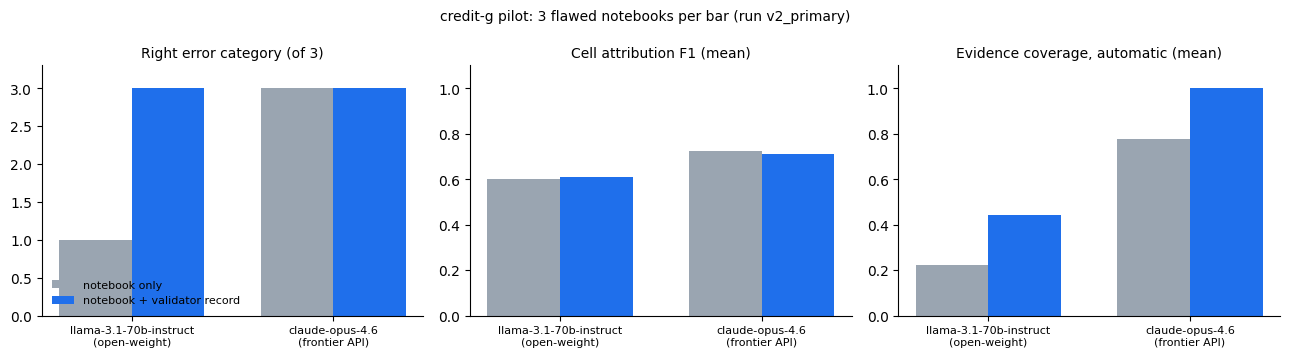

In [18]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (col, title, top) in zip(axes, [("right_category", "Right error category (of 3)", 3),
                                        ("cell_F1", "Cell attribution F1 (mean)", 1),
                                        ("evidence_coverage_auto", "Evidence coverage, automatic (mean)", 1)]):
    data = summary[col].unstack("condition")
    x = np.arange(len(data))
    for j, (cond, color) in enumerate([("C1", "#9aa5b1"), ("C2", "#1f6feb")]):
        ax.bar(x + (j - 0.5) * 0.36, data[cond], 0.36, label={"C1": "notebook only", "C2": "notebook + validator record"}[cond], color=color)
    ax.set_xticks(x, [f"{MODELS[m].split('/')[1]}\n({MODEL_ROLES[m]})" for m in data.index], fontsize=8)
    ax.set_ylim(0, top * 1.1)
    ax.set_title(title, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(fontsize=8, frameon=False, loc="lower left")
fig.suptitle(f"credit-g pilot: 3 flawed notebooks per bar (run {RUN_ID})", fontsize=10)
fig.tight_layout()
fig.savefig(REPORT / "credit_g_c1_vs_c2.png", dpi=200)
plt.show()

In [19]:
# answer texts, side by side per notebook
for label in ["E1", "E2", "E3", "correct"]:
    iid = IID[label]
    print(f"\n{'=' * 22} {label} ({iid}) {'=' * 22}")
    for slot in MODELS:
        for cond in ("C1", "C2"):
            d = read_json(RUNS / f"{iid}__{slot}__{cond}.json")
            r = d["response"]
            print(f"--- {MODELS[slot]} · {cond}")
            if r is None:
                print("    (invalid output)")
                continue
            print(f"    error: {r['error_present']} | category: {r['error_category']} | cells: {r['affected_cell_ids']}")
            for c in r["evidence_claims"]:
                print(f"    claim {c['cell_ids']}: {c['claim']}")
            print(f"    explanation: {r['methodological_explanation']}")
            print(f"    hint: {r['next_step_hint']}")


====================== E1 (credit_g_instance_3) ======================
--- meta-llama/llama-3.1-70b-instruct · C1
    error: True | category: preprocessing_leakage | cells: ['cell_02', 'cell_05']
    claim ['cell_02']: The notebook joins the applicants data with account reviews data without any filtering or validation.
    claim ['cell_05']: The preprocessing pipeline uses the entire dataset to scale and one-hot encode features, without separating training and testing data.
    explanation: Preprocessing leakage occurs when the preprocessing steps are applied to the entire dataset, including the test set, which can lead to overestimation of the model's performance. In this case, the notebook joins the applicants data with account reviews data without any filtering or validation, and then uses the entire dataset to scale and one-hot encode features. This can cause the model to learn from the test data, resulting in overly optimistic performance estimates.
    hint: Separate the trainin

In [20]:

def md_table(df):
    df = df.reset_index()
    lines = ["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(f"{v:.3f}" if isinstance(v, float) else str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)

report = f"""# TraceableDS - credit-g pilot ({RUN_ID})

Generated {now()} · protocol frozen {protocol['frozen_utc']} · scorer v{SCORING_VERSION}

**Models:** {', '.join(f"{MODELS[s]} ({MODEL_ROLES[s]})" for s in MODELS)} via OpenRouter, temperature 0.

## Benchmark
{md_table(effects)}

E1 column agreement with the target (measured): {lineage[0]['measured_agreement_with_target']}

## Validator matrix
{md_table(matrix)}

## Condition 1 (notebook) vs. Condition 2 (notebook + validator record), flawed notebooks
{md_table(summary)}

## Right category per error family
{md_table(per_family)}

## Deviations from the proposal
""" + "\n".join(f"- {d}" for d in protocol["deviations_from_proposal"]) + """

## Open decisions
- VAL_01 reports the entry cell and the fit cell; gold relevant cells for E1 are cell_02 and cell_03.
- Scoring rule for invalid or inconsistent outputs; manual adjudication of Metric 3/4 sheets.
- Two independent reviewers (A6) and the remaining three datasets.
"""
(REPORT / "credit_g_summary.md").write_text(report)
write_json(REPORT / "credit_g_run_log.json", {"run_id": RUN_ID, "protocol": protocol, "summary": summary.reset_index().to_dict("records"),
                                               "overview": overview.to_dict("records")})
print("Saved:", REPORT / "credit_g_summary.md", "|", REPORT / "credit_g_c1_vs_c2.png")

Saved: /content/drive/MyDrive/traceableds_v2/report/credit_g_summary.md | /content/drive/MyDrive/traceableds_v2/report/credit_g_c1_vs_c2.png


## Outputs
| Folder | Content |
|---|---|
| `benchmark/credit_g/` | model-facing notebooks (`credit_g_instance_1..4`), `applicants.csv`, `account_reviews.csv` |
| `meta/credit_g/` | dataset card, lineage, manifest, traces, validator records, gold annotations (hidden from the LLM) |
| `protocol/` | frozen protocol and its components |
| `prompts/credit_g/` | the exact 8 prompts sent |
| `runs/` | 16 LLM responses (all attempts, provider, tokens) and 4 baseline outputs |
| `scoring/` | `scores.csv`, `metric3_claims.csv`, `metric4_points.csv` (fill `manual_decision`, then re-run § 9–10) |
| `report/` | summary for the review meeting, figure, run log |